In [ ]:
from TH_ffid_ldv.spectra import non_uniform_spectra

In [3]:
import pandas as pd
from TH_ffid_ldv.dataIo import load_lda_point
from TH_ffid_ldv.ffid import ffid_calibration_func, shift_ffid_signal
from TH_ffid_ldv.utilities import extract_date_from_filepath

import xarray as xr
from matplotlib import pyplot as plt
import numpy as np
%matplotlib widget

In [12]:
main_files=pd.read_csv('../data/main_files_lst.csv')
path=main_files.iloc[80]['file_path']
print(path)

../data/raw/LDA/2024_11_04/TH_F0Z110_Y_lpm_400_40hz\VEL_TH_F0Z110_Y_lpm_400_40hz.000077.txt


In [13]:
data = shift_ffid_signal(load_lda_point(path))
data = data.rename_dims({'t':'time'})

In [14]:
from TH_ffid_ldv.utilities import get_corresponding_ffid_file
from TH_ffid_ldv.ffid import ffid_signal_conditioning
from TH_ffid_ldv.dataIo import load_lda_point, load_ffid_data
from scipy.signal import welch, correlate
ffid_ldv_df = pd.read_csv('../data/ffid_ldv_comparison_main_files.csv')
ffid_ldv_df.set_index('path', inplace=True)
time_shift = ffid_ldv_df.loc[path]['time_shift']
ffid_path = get_corresponding_ffid_file(path)
data_ffid = load_ffid_data(ffid_path)
delta_t = data.t.max() - data.t.min()
data_ffid = data_ffid.where((data_ffid.t >= time_shift) &
							(data_ffid.t <= time_shift + delta_t), drop=True)
data_ffid = ffid_signal_conditioning(data_ffid, dt=0)

C:\Users\Lior\AppData\Local\Temp\ipykernel_65852\634647792.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


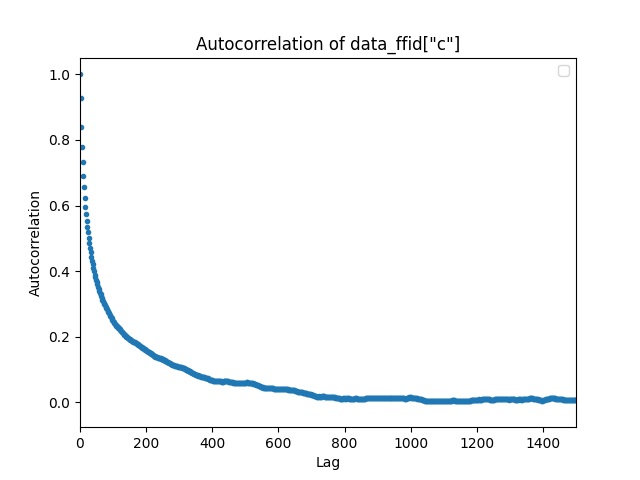

In [15]:
from scipy.signal import savgol_filter

# Calculate autocorrelation function of data_ffid['c']
c = data_ffid['c'].values
# Use only the first 1/5th of the signal for autocorrelation
n = 60/(2e-3)
# autocorr = correlate(c[:n] - np.mean(c[:n]), c[:n] - np.mean(c[:n]), mode='full', method='direct')
# Take a 1-minute segment (1 min = 60 sec, dt = 2 ms = 0.002 s, so n_seg = 60/0.002 = 30000 samples)
n_seg = int(60 / 0.002)
segment = c
autocorr = correlate(segment - np.mean(segment), segment - np.mean(segment), mode='full')
autocorr = autocorr[autocorr.size // 2:]  # keep only non-negative lags
lags = np.arange(0, len(autocorr))
# # Normalize
autocorr /= np.max(autocorr)
# # Plot
plt.figure()
plt.plot(lags*2, autocorr,'.')
plt.xlabel('Lag')
plt.xlim((0,1500))
# autocorr_smooth = savgol_filter(autocorr, window_length=1000, polyorder=2)
# plt.axhline(y=0, color='k')
# plt.plot(lags*2, autocorr_smooth/autocorr_smooth.max(), label='Smoothed', color='red', ls='--')
plt.legend()
plt.ylabel('Autocorrelation')
plt.title('Autocorrelation of data_ffid["c"]')
plt.show()

In [16]:
t = data['t'].values*1e-3
u = data['c'].values
w = data['transit_time'].values*1e-6
K2 = 200
dt = np.median(np.diff(t))
print(1/dt)

468.6035613906083


In [ ]:
tau, R, f, S = non_uniform_spectra(t, u, w, dt, 1024*10, meanrem=True, atw=False, locnor=True, selfproducts=False)


In [1]:

# 4. Plotting
plt.figure(figsize=(6, 6))

# Sorting tau for a clean line plot
sort_idx = np.argsort(tau)
R_normalized = np.real(R) / np.max(np.real(R))
plt.plot(tau[sort_idx] * 1000, R_normalized[sort_idx], 'b-o', markersize=3, label='Estimated ACF')
plt.plot(lags*2, autocorr,'-r')

plt.title('Autocorrelation Function from Randomly Sampled Data')
plt.xlabel('Lag Time τ [ms]')
plt.ylabel('Mean Autocorrelation R [m²/s²]')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()

# Matching the paper's visualization style [cite: 596]
plt.axvline(0, color='black', linewidth=1)
plt.axhline(0, color='black', linewidth=1)
plt.axhline(1/np.exp(1), color='red', linestyle='--', label='-1/e Decay')
plt.xlim((0,1500))

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [90]:
S[pos_mask]

IndexError: boolean index did not match indexed array along axis 0; size of axis is 20481 but size of corresponding boolean axis is 10240

(0.1, 250.0)

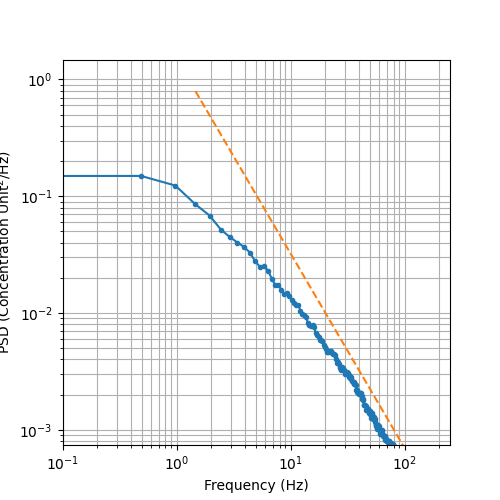

In [94]:
fig,ax = plt.subplots(figsize=(5, 5))
nperseg=2048/2
data_ffid["c'"] = data_ffid['c'] - data_ffid['c'].mean(dim='t')
frequencies, psd = welch(
	data_ffid["c'"],
	fs=500,
	nperseg=nperseg,
	scaling='spectrum'  # 'density' gives units like V**2/Hz or (conc_unit)**2/Hz
)
cc = (data_ffid["c'"]**2).mean(dim='t').values
if ax is None:
	fig, ax = plt.subplots(figsize=(5, 5))
# 5. Plot the Spectrum (Power Spectral Density)
ax.loglog(frequencies, psd/cc, marker='.') # Use a logarithmic y-axis for 
ax.loglog(frequencies[frequencies>=1], 1.5*frequencies[frequencies>=1]**(-5/3),ls='--') # Use a logarithmic y-axis for the PSD
# Alternatively, for a log-log plot (common in turbulence):
# plt.loglog(frequencies, psd)
ax.set_ylabel("PSD (Concentration Unit$^2$/Hz)") # Adjust unit based on your signal
ax.set_xlabel("Frequency (Hz)")
ax.grid(True, which="both", ls="-") # Grid for both major and minor ticks
pre_multiplied = frequencies*psd/cc
ax.set_ylim(bottom=np.min(pre_multiplied[frequencies>0.1])/10 , top=np.max(pre_multiplied)*10 ) # Avoid zero or negative limits on log scale
ax.set_xlim(0.1, 500 / 2) # Plot up to Nyquist frequency

C:\Users\Lior\AppData\Local\Temp\ipykernel_59508\683708763.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


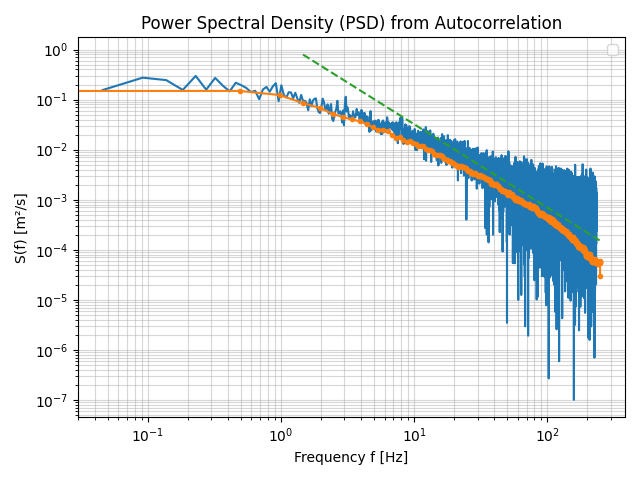

In [99]:
# 4. Filter for Positive Frequencies
# The FFT returns both positive and negative frequencies; PSD is symmetric
# df is the frequency resolution
K=10*1024
R = R/R.max()
df = 1 / float(K * dt)
# f is the frequency axis
f = np.roll(np.arange(-(K // 2), K - (K // 2)), -(K // 2)) * df
# S is the PSD calculated via FFT of the Autocorrelation R
S = dt * np.fft.fft(R)
# 5. Plotting
S_truncated = S[:len(f)] 

# 2. Now create the mask based on the correct length
pos_mask = f > 0

# 3. Apply the mask to both vectors
f_plot = f[pos_mask]
S_plot = np.abs(S_truncated[pos_mask])

plt.figure()
# 4. Plot on log-log scale
plt.loglog(f_plot, S_plot)
plt.loglog(frequencies, psd/cc, marker='.') # Use a logarithmic y-axis for 
plt.loglog(frequencies[frequencies>=1], 1.5*frequencies[frequencies>=1]**(-5/3),ls='--') # Use a logarithmic y-axis for the PSD

# 3. Add labels and grid
plt.title('Power Spectral Density (PSD) from Autocorrelation')
plt.xlabel('Frequency f [Hz]')
plt.ylabel('S(f) [m²/s]')
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()